# Data Overview

This analysis uses the 'Consumer Complaints Database' dataset. It covers financial services complaints from 1 December 2011 to 15 November 2017.

Our goal here is to understand the data - columns, data types, missing values, duplicates, etc.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/consumer_complaints.csv')

## Understanding the Data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 903983 entries, 0 to 903982
Data columns (total 18 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   Date received                 903983 non-null  str  
 1   Product                       903983 non-null  str  
 2   Sub-product                   668823 non-null  str  
 3   Issue                         903983 non-null  str  
 4   Sub-issue                     426386 non-null  str  
 5   Consumer complaint narrative  199970 non-null  str  
 6   Company public response       257981 non-null  str  
 7   Company                       903983 non-null  str  
 8   State                         894758 non-null  str  
 9   ZIP code                      894705 non-null  str  
 10  Tags                          126038 non-null  str  
 11  Consumer consent provided?    375434 non-null  str  
 12  Submitted via                 903983 non-null  str  
 13  Date sent to company     

The dataset contains 18 columns, 903,983 rows.

There are 17 str data types, and 1 integer. Upon first look:
- 'Date received' and 'Date sent to company' need to be converted to Datetime

## Unique values

In [3]:
df.nunique()

Date received                     2176
Product                             18
Sub-product                         75
Issue                              166
Sub-issue                          217
Consumer complaint narrative    195317
Company public response             10
Company                           4504
State                               62
ZIP code                         28785
Tags                                 3
Consumer consent provided?           4
Submitted via                        6
Date sent to company              2125
Company response to consumer         8
Timely response?                     2
Consumer disputed?                   2
Complaint ID                    903983
dtype: int64

In [4]:
product_unique = df['Product'].unique()

product_unique

<StringArray>
[                                                                    'Mortgage',
                                                             'Credit reporting',
                                                                'Consumer Loan',
                                                                  'Credit card',
                                                              'Debt collection',
                                                                 'Student loan',
                                                      'Bank account or service',
                                                      'Other financial service',
                                                                 'Prepaid card',
                                                              'Money transfers',
 'Credit reporting, credit repair services, or other personal consumer reports',
                                                                  'Payday loan',
              

In [5]:
state_unique = df['State'].unique()

state_unique

<StringArray>
['MI', 'AL', 'PA', 'ID', 'VA', 'MN', 'CA', 'FL', 'TX', 'NV', 'NY', 'NE', 'MT',
 'ME', 'WI', 'WA', 'RI', 'NJ', 'IL', 'MS', 'OH', 'GA', 'MD', 'MA', 'SC', 'CO',
 'SD', 'LA', 'OR', 'IA', 'IN', 'NC', 'TN', 'VT', 'AZ', 'DE',  nan, 'MO', 'KS',
 'WV', 'HI', 'ND', 'CT', 'WY', 'NH', 'MP', 'DC', 'NM', 'KY', 'UT', 'AR', 'OK',
 'PR', 'AP', 'AK', 'VI', 'MH', 'AA', 'AE', 'GU', 'FM', 'AS', 'PW']
Length: 63, dtype: str

Included in States column:
- 50 States
- District of Columbia (DC)
- US territories (AS, GU, MP, PR, VI)
- Military addresses (AA, AE, AP)
- Missing values (nan)

In [6]:
print(f'Missing values count: {df['State'].isna().sum()}')
print(f'Military address (AA) count: {(df['State'] == 'AA').sum()}')
print(f'Military address (AE) count: {(df['State'] == 'AE').sum()}')
print(f'Military address (AP) count: {(df['State'] == 'AP').sum()}')
print(f'US Territories (AS) count: {(df['State'] == 'AS').sum()}')
print(f'US Territories (GU) count: {(df['State'] == 'GU').sum()}')
print(f'US Territories (MP) count: {(df['State'] == 'MP').sum()}')
print(f'US Territories (PR) count: {(df['State'] == 'PR').sum()}')
print(f'US Territories (VI) count: {(df['State'] == 'VI').sum()}')

Missing values count: 9225
Military address (AA) count: 15
Military address (AE) count: 371
Military address (AP) count: 260
US Territories (AS) count: 25
US Territories (GU) count: 139
US Territories (MP) count: 31
US Territories (PR) count: 2351
US Territories (VI) count: 200


In [7]:
public_response_unique = df['Company public response'].unique()
public_response_unique

<StringArray>
[                                                                                                                      nan,
                         'Company has responded to the consumer and the CFPB and chooses not to provide a public response',
                                                'Company believes it acted appropriately as authorized by contract or law',
                                                                        'Company chooses not to provide a public response',
                                                              'Company can't verify or dispute the facts in the complaint',
                                                                   'Company disputes the facts presented in the complaint',
                                                      'Company believes the complaint is the result of a misunderstanding',
 'Company believes complaint caused principally by actions of third party outside the control or direction of the comp

In [8]:
submitted_channels = df['Submitted via'].unique()
submitted_channels

<StringArray>
['Referral', 'Web', 'Phone', 'Fax', 'Postal mail', 'Email']
Length: 6, dtype: str

In [9]:
company_response_unique = df['Company response to consumer'].unique()
company_response_unique

<StringArray>
[        'Closed with explanation',     'Closed with monetary relief',
           'Closed without relief', 'Closed with non-monetary relief',
              'Closed with relief',                          'Closed',
               'Untimely response',                     'In progress']
Length: 8, dtype: str

In [10]:
timely_response_unique = df['Timely response?'].unique()
print(timely_response_unique)

timely_response_counts = df['Timely response?'].value_counts()
print(timely_response_counts)

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Timely response?
Yes    879376
No      24607
Name: count, dtype: int64


In [11]:
consumer_disputed_unique = df['Consumer disputed?'].unique()
print(consumer_disputed_unique)

consumer_disputer_count = df['Consumer disputed?'].value_counts()
print(consumer_disputer_count)

<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
Consumer disputed?
No     620197
Yes    148378
Name: count, dtype: int64


## Missing values and duplicates

In [12]:
missing_values_count = df.isna().sum()
missing_values_count

Date received                        0
Product                              0
Sub-product                     235160
Issue                                0
Sub-issue                       477597
Consumer complaint narrative    704013
Company public response         646002
Company                              0
State                             9225
ZIP code                          9278
Tags                            777945
Consumer consent provided?      528549
Submitted via                        0
Date sent to company                 0
Company response to consumer         0
Timely response?                     0
Consumer disputed?              135408
Complaint ID                         0
dtype: int64

In [13]:
duplicates_count = df.duplicated().sum()
duplicates_count

np.int64(0)

The dataset doesn't contain duplicates.

There are columns with many missing values. Coincidentally, most of the columns that have a lot of missing values aren't needed for this analysis.

Columns and missing values will be handled in the next notebook.

## Distributions

Text(0, 0.5, 'Number of Values')

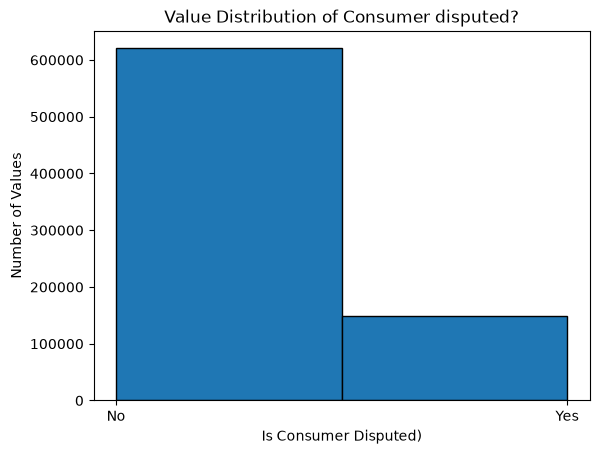

In [14]:
plt.hist(df['Consumer disputed?'].dropna(), bins=2, edgecolor='black')

plt.title('Value Distribution of Consumer disputed?')
plt.xlabel('Is Consumer Disputed)')
plt.ylabel('Number of Values')

In [17]:
df['Date received'] = pd.to_datetime(df['Date received'])
df['year'] = df['Date received'].dt.year

missing_by_year = (
    df.groupby('year')['Consumer disputed?']
    .apply(lambda x: x.isna().mean() * 100)
)

print(missing_by_year)

year
2011     0.000000
2012     0.000000
2013     0.000000
2014     0.000000
2015     0.000000
2016     0.000000
2017    65.169556
Name: Consumer disputed?, dtype: float64
